In [1]:
import pandas as pd, numpy as np, re, os, time
from itertools import combinations
import matplotlib.pyplot as plt
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)

CANDIDATES = ['nc_merged_customers.csv', '1792312434490_nc_merged_customers.csv',
              '/mnt/user-data/uploads/1792312434490_nc_merged_customers.csv']
DATA_PATH = next(p for p in CANDIDATES if os.path.exists(p))
df = pd.read_csv(DATA_PATH, low_memory=False)
print(df.shape)

(185000, 16)


## 1. Name formats (the key finding)
The EDA showed Billing names are shorter. Here is why: Billing mixes three formats, CRM uses only `First [M.] Last`.

In [2]:
n = df.full_name
fmt = np.select([n.str.contains(','), n.str.isupper() & n.str.contains(' ')], ['Last, First', 'LAST FIRST (uppercase)'], 'First Last')
print(pd.crosstab(df.source_system, fmt, normalize='index').round(3))
print()
for f in ['Last, First', 'LAST FIRST (uppercase)', 'First Last']:
    print(f, '->', df.full_name[fmt==f].head(4).tolist())
print('Initial-first names (K. Hall):', n.str.match(r'^[A-Z]\. ').groupby(df.source_system).mean().round(3).to_dict())

col_0          First Last  LAST FIRST (uppercase)  Last, First
source_system                                                 
BILLING             0.635                   0.183        0.183
CRM                 1.000                   0.000        0.000

Last, First -> ['Nunez, Ana', 'Pagan Galarza, Mnuel', 'Clark, Elhjah', 'Belkin, Naida']
LAST FIRST (uppercase) -> ['BARNWELL HAELY', 'DIXON JNE', 'MULLINS STEIE', 'COMPTON SHIRLYE']
First Last -> ['Nathan Nance', 'Jonathan L. Henson', 'Dylan H. Wilkerson', 'Frankie King']
Initial-first names (K. Hall): {'BILLING': 0.184, 'CRM': 0.0}


## 2. Cleaning functions
- **Phone:** keep 10 digits; drop leading 1; set placeholders and phones shared by 20+ records (e.g. `336-000-0000`) to missing.
- **Address:** lowercase, remove punctuation, expand abbreviations to one form (`Avenue`/`Ave` -> `ave`); the shared address `700 E Haggard Ave` is ignored.
- **Name:** parse the 3 formats into `first` and `last`; remove apostrophes and hyphens (`D'Marcus`, `Lili-Anne`) so they stay one word; strip suffixes and middle initials.
- **Email:** the part before `@` (domain changes between duplicates).
- **Soundex:** a phonetic code so that `Wrenn`, `Wrrenn`, `Wrennn` give the same key.

In [3]:
def norm_phone(p):
    if pd.isna(p): return np.nan
    d = re.sub(r'\D', '', p)
    if len(d) == 11 and d[0] == '1': d = d[1:]
    return d if len(d) == 10 else np.nan

ABBR = {'avenue':'ave','street':'st','drive':'dr','road':'rd','lane':'ln','court':'ct','boulevard':'blvd','circle':'cir',
        'place':'pl','highway':'hwy','trail':'trl','terrace':'ter','parkway':'pkwy','north':'n','south':'s','east':'e','west':'w'}
def norm_addr(a):
    if pd.isna(a): return np.nan
    t = re.sub(r'[^a-z0-9 ]', ' ', a.lower()).split()
    return ' '.join(ABBR.get(x, x) for x in t)

SUF = {'jr','sr','ii','iii','iv'}
def parse_name(n):
    n = re.sub(r"['’-]", '', n.strip())          # D'Marcus -> DMarcus, Lili-Anne -> LiliAnne (same form on both sides)
    if ',' in n:                                    # "Last, First"
        last, first = [x.strip() for x in n.split(',', 1)]
        ft = re.sub(r'[^a-z ]', ' ', first.lower()).split(); lt = re.sub(r'[^a-z ]', ' ', last.lower()).split()
        return (ft[0] if ft else '', ' '.join(lt))
    if n.isupper() and ' ' in n:                    # "LAST FIRST"
        t = re.sub(r'[^a-z ]', ' ', n.lower()).split()
        return (t[-1], ' '.join(t[:-1]))
    t = [x for x in re.sub(r'[^a-z ]', ' ', n.lower()).split() if x not in SUF]   # "First [M.] Last"
    return (t[0], '') if len(t) == 1 else (t[0], t[-1])

def soundex(s):
    s = re.sub(r'[^a-z]', '', str(s).lower())
    if not s: return ''
    m = {**dict.fromkeys('bfpv','1'), **dict.fromkeys('cgjkqsxz','2'), **dict.fromkeys('dt','3'), 'l':'4', **dict.fromkeys('mn','5'), 'r':'6'}
    out = s[0].upper(); prev = m.get(s[0], '')
    for ch in s[1:]:
        c = m.get(ch, '')
        if c and c != prev: out += c
        if ch not in 'hw': prev = c
    return (out + '000')[:4]

print(soundex('Wrenn'), soundex('Wrrenn'), soundex('Wrennn'), soundex('Wreenn'), '| Robert', soundex('Robert'), soundex('Rupert'))

W650 W650 W650 W650 | Robert R163 R163


In [4]:
d = df.copy()
d['phone_c'] = d.phone.map(norm_phone)
vc = d.phone_c.value_counts()
bad_phones = set(vc[vc >= 20].index) | {'3360000000','9999999999','0000000000'}
print('Placeholder / over-shared phones removed:', len(bad_phones), '| rows affected:', d.phone_c.isin(bad_phones).sum())
d.loc[d.phone_c.isin(bad_phones), 'phone_c'] = np.nan

d['addr_c'] = d.address.map(norm_addr)
d.loc[d.address == '700 E Haggard Ave', 'addr_c'] = np.nan     # shared placeholder address

nm = d.full_name.map(parse_name)
d['first'] = [x[0] for x in nm]; d['last'] = [x[1] for x in nm]
d['last_core'] = d['last'].str.split().str[-1]
d['first_init'] = d['first'].str[:1]
d['last_sdx'] = d.last_core.map(soundex)

d['em_local']   = d.email.str.split('@').str[0].str.lower()
d['em_digits']  = d.em_local.str.extract(r'(\d+)$')[0]
d['em_letters5'] = d.em_local.str.replace(r'[^a-z]', '', regex=True).str[:5]

d[d.true_customer_id == 'CUST006319'][['full_name','first','last','phone_c','addr_c','em_local','last_sdx']]

Placeholder / over-shared phones removed: 8 | rows affected: 855


,full_name,first,last,phone_c,addr_c,em_local,last_sdx
27,Tammy S. Wrrenn,tammy,wrrenn,3366750998,NaN,tammywrenn82,W650
18730,Tammy S. Wrenn,tammy,wrenn,3366750998,514 texas ave,tammywrenn82,W650
108045,Tammy Wrennn,tammy,wrennn,3366750998,514 texas ave,tammywrenn82,W650
181065,Tammy Wreenn,tammy,wreenn,3366750998,514 texas ave,tammywrenn82,W650


In [5]:
before = df.groupby('true_customer_id').size()
print('Distinct raw phones :', df.phone.nunique(), '-> cleaned:', d.phone_c.nunique())
print('Distinct raw addrs  :', df.address.nunique(), '-> cleaned:', d.addr_c.nunique())
print('Distinct raw names  :', df.full_name.nunique(), '-> (first,last) pairs:', d[['first','last']].drop_duplicates().shape[0])

Distinct raw phones : 102366 -> cleaned: 65679
Distinct raw addrs  : 83919 -> cleaned: 65297
Distinct raw names  : 153962 -> (first,last) pairs: 131534


## 3. Ground-truth pairs (for evaluation only)

In [6]:
true_pairs = set()
for k, idx in d.groupby('true_customer_id').indices.items():
    for a, b in combinations(sorted(idx), 2): true_pairs.add((a, b))
total_pairs = len(d) * (len(d) - 1) // 2
print(f'True duplicate pairs: {len(true_pairs):,} | all possible pairs: {total_pairs:,}')

True duplicate pairs: 118,116 | all possible pairs: 17,112,407,500


## 4. Blocking
A **block key** groups records; only records sharing a key become candidate pairs. Huge blocks (> 60 records, e.g. big apartment buildings) are skipped because they create too many useless pairs.

| Key | Idea |
|---|---|
| B1 | email local part (before `@`) |
| B2 | cleaned phone |
| B3 | zip + last-name soundex + first initial (handles typos and name order) |
| B4 | cleaned address + zip |
| B5 | first 5 email letters + trailing digits + zip (handles email typos) |

**Metrics:** *recall* = share of true duplicate pairs kept (want ~100%); *precision* = share of candidate pairs that are real (the classifier in step 4 will clean this up); *reduction* = share of all pairs removed.

In [7]:
def make_pairs(frame, keycols, cap=60):
    kc = [keycols] if isinstance(keycols, str) else keycols
    sub = frame.dropna(subset=kc)
    key = sub[kc].astype(str).agg('|'.join, axis=1)
    pairs, skipped = set(), 0
    for k, idx in key.groupby(key).indices.items():
        if len(idx) < 2: continue
        if len(idx) > cap: skipped += 1; continue
        for a, b in combinations(sorted(sub.index.values[idx]), 2): pairs.add((a, b))
    return pairs, skipped

BLOCKS = {'B1 email local part': 'em_local',
          'B2 phone (cleaned)': 'phone_c',
          'B3 zip + last soundex + first initial': ['zip_code','last_sdx','first_init'],
          'B4 address + zip': ['addr_c','zip_code'],
          'B5 email letters(5) + digits + zip': ['em_letters5','em_digits','zip_code']}
allp, rows = {}, []
for name, kc in BLOCKS.items():
    t = time.time(); p, sk = make_pairs(d, kc); allp[name] = p; tp = len(p & true_pairs)
    rows.append((name, len(p), tp, tp/len(true_pairs), tp/max(len(p),1), 1-len(p)/total_pairs, sk, round(time.time()-t,1)))
res = pd.DataFrame(rows, columns=['block','candidate_pairs','true_pairs_kept','recall','precision','reduction','big_blocks_skipped','sec'])
res.round(4)

,block,candidate_pairs,true_pairs_kept,recall,precision,reduction,big_blocks_skipped,sec
0,B1 email local part,88414,88404,0.7485,0.9999,1.0,0,15.7
1,B2 phone (cleaned),101221,82783,0.7009,0.8178,1.0,0,8.0
2,B3 zip + last soundex + first initial,558578,111801,0.9465,0.2002,1.0,5,14.6
3,B4 address + zip,275106,92773,0.7854,0.3372,1.0,1,13.6
4,B5 email letters(5) + digits + zip,140369,102383,0.8668,0.7294,1.0,0,15.3


,keys_combined,candidate_pairs,true_pairs_kept,recall,precision,reduction
0,B1..B1,88414,88404,0.74845,0.99989,0.99999
1,B1..B2,126953,108505,0.91863,0.85469,0.99999
2,B1..B3,581733,117412,0.99404,0.20183,0.99997
3,B1..B4,746427,117895,0.99813,0.15795,0.99996
4,B1..B5,784350,117988,0.99892,0.15043,0.99995


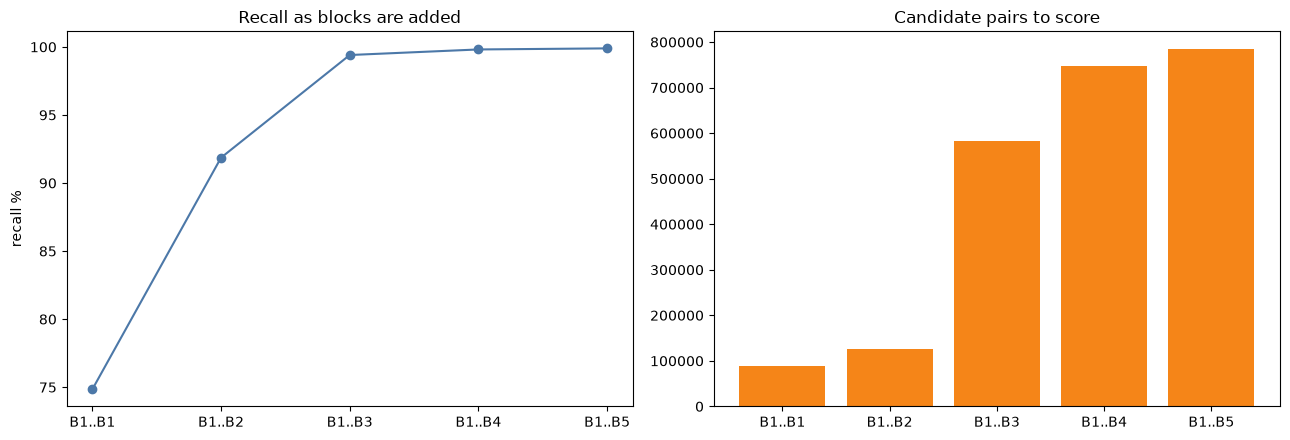

In [8]:
names = list(BLOCKS); rows = []
for i in range(1, len(names)+1):
    u = set().union(*[allp[n] for n in names[:i]]); tp = len(u & true_pairs)
    rows.append((f'B1..B{i}', len(u), tp, tp/len(true_pairs), tp/len(u), 1-len(u)/total_pairs))
cum = pd.DataFrame(rows, columns=['keys_combined','candidate_pairs','true_pairs_kept','recall','precision','reduction'])
display(cum.round(5))

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(cum.keys_combined, cum.recall*100, marker='o', color='#4C78A8'); ax[0].set_ylabel('recall %'); ax[0].set_title('Recall as blocks are added')
ax[1].bar(cum.keys_combined, cum.candidate_pairs, color='#F58518'); ax[1].set_title('Candidate pairs to score'); 
plt.tight_layout(); plt.show()

## 5. Final candidate set and what was missed

In [9]:
cand = set().union(*allp.values())
missed = true_pairs - cand
print(f'Candidate pairs: {len(cand):,}  (vs {total_pairs:,} all pairs -> {1-len(cand)/total_pairs:.4%} removed)')
print(f'True pairs kept: {len(cand & true_pairs):,} / {len(true_pairs):,}  recall = {len(cand & true_pairs)/len(true_pairs):.4%}')
print(f'Missed true pairs: {len(missed):,}')
for a, b in list(missed)[:5]:
    display(df.loc[[a, b], ['record_id','full_name','email','phone','address','zip_code']])

Candidate pairs: 784,350  (vs 17,112,407,500 all pairs -> 99.9954% removed)
True pairs kept: 117,988 / 118,116  recall = 99.8916%
Missed true pairs: 128


,record_id,full_name,email,phone,address,zip_code
64355,CRM0064356,Jack Agner,jack.agner65@post.example,(434) 792-0170,2030 Gurney Ct,27215
108567,BIL0008568,J. Abner,jack.agner5@post.example,NaN,NaN,27215


,record_id,full_name,email,phone,address,zip_code
62927,CRM0062928,James Pater,NaN,NaN,1319 Reading CCt,27217
180524,BIL0080525,James Panter,jpanter56@example.net,NaN,1319 Reading Ct,27217


,record_id,full_name,email,phone,address,zip_code
82204,CRM0082205,Arnetta Girardeau,arnetta_girardeau69@mail.example,NaN,1105 Olympic Dr,27302
184525,BIL0084526,GIRADEAU ARNETTA,arnetta_girardeau9@mail.example,NaN,1105 Olymmpic Dr,27302


,record_id,full_name,email,phone,address,zip_code
76109,CRM0076110,Noah Swoveladn,nswoveland35@example.com,9103589688,1056 Knollridge Drive,27217
142067,BIL0042068,Nah Swoveland,nswwoveland35@example.com,NaN,1056 Knolridge Drive,27217


,record_id,full_name,email,phone,address,zip_code
2470,CRM0002471,Le'iKta Richardson,NaN,NaN,351 Armistead Court,27217
116669,BIL0016670,L. Rifhardson,lekitarichardson40@example.org,NaN,351 Armistead CCt,27217


In [10]:
# save outputs for step 3
d.drop(columns=['phone_miss'], errors='ignore').to_csv('cleaned_customers.csv', index=False)
pd.DataFrame(sorted(cand), columns=['idx_a','idx_b']).to_csv('candidate_pairs.csv', index=False)
print('saved cleaned_customers.csv and candidate_pairs.csv (row positions of d)')

saved cleaned_customers.csv and candidate_pairs.csv (row positions of d)


## 6. Results and next step
- Name format was the biggest hidden problem: Billing has `Last, First` (18%) and `LAST FIRST` (18%). Parsing it lifts the zip + soundex block from about 40% recall to about 95%.
- Combined blocks keep about **99.9% of true duplicate pairs** while removing about **99.995%** of the 17 billion pairs.
- Precision is low (about 15%) by design: blocking only needs to be *safe*. Step 3 scores each candidate pair (Jaro-Winkler / Levenshtein on name, email, phone, address), and step 4 trains a classifier on these scores.
- Nicknames (`Kate` vs `Katherine`) and swapped letters inside the email are the main reasons for the few missed pairs; a nickname table can be added in step 3.